# ML — Supervised Learning
### Data Science Core Concepts 101 — by Yunhan Jin

Supervised learning trains a model on labeled data — each row has an input (features X) and a known output (target y). The model learns the mapping from X → y, then predicts y for new, unseen data.

Two main tasks:
- **Regression**: predict a continuous value — e.g. house price, temperature, revenue
- **Classification**: predict a class label — e.g. spam/not spam, high-value/not, churn/not

This notebook uses the same housing dataset from EDA and Feature Engineering.

---

## Section 1: Setup

### 1.1 Load and Prepare Data
We recreate the housing dataset from scratch with all feature engineering applied. Two targets are defined:
- `log_price` — regression target (log-transformed price)
- `high_value` — classification target (1 if price > median, else 0)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
n = 500
neighborhoods = ['Downtown', 'Midtown', 'Uptown', 'Suburbs', 'Riverside'] * (n // 5)
conditions = ['Poor', 'Fair', 'Good', 'Excellent']

df = pd.DataFrame({
    'sqft': np.random.normal(1800, 400, n).astype(int).clip(600, 4000),
    'bedrooms': np.random.choice([2, 3, 4, 5], n, p=[0.2, 0.4, 0.3, 0.1]),
    'neighborhood': neighborhoods,
    'condition': np.random.choice(conditions, n, p=[0.1, 0.2, 0.5, 0.2]),
    'year_built': np.random.randint(1960, 2020, n),
    'has_garage': np.random.choice([True, False], n, p=[0.7, 0.3]),
    'listing_date': pd.date_range('2020-01-01', periods=n, freq='D'),
})

hood_price = {'Downtown': 1.3, 'Midtown': 1.1, 'Uptown': 1.0, 'Suburbs': 0.9, 'Riverside': 1.05}
cond_price  = {'Poor': 0, 'Fair': 1, 'Good': 2, 'Excellent': 3}

df['price'] = (
    80000
    + df['sqft'] * 120
    + df['bedrooms'] * 8000
    + df['condition'].map(cond_price) * 15000
    + df['has_garage'].astype(int) * 12000
    + np.random.normal(0, 20000, n)
) * df['neighborhood'].map(hood_price)
df['price'] = df['price'].clip(100000, 1000000).astype(int)

# Feature engineering
df['condition_encoded'] = df['condition'].map({'Poor': 0, 'Fair': 1, 'Good': 2, 'Excellent': 3})
df = pd.get_dummies(df, columns=['neighborhood'], drop_first=True)
df['has_garage']    = df['has_garage'].astype(int)
df['house_age']     = 2024 - df['year_built']
df['listing_month'] = df['listing_date'].dt.month
df['is_summer']     = df['listing_month'].isin([6, 7, 8]).astype(int)
df['log_price']     = np.log(df['price'])
df['high_value']    = (df['price'] > df['price'].median()).astype(int)

print(f'Dataset shape: {df.shape}')
print(f'Regression target: log_price | Classification target: high_value')
df[['price', 'log_price', 'high_value']].head()

Dataset shape: (500, 17)
Regression target: log_price | Classification target: high_value


,price,log_price,high_value
0,479290,13.080061,1
1,325838,12.694156,0
2,343604,12.747245,0
3,370499,12.822606,0
4,376956,12.839884,1


### 1.2 Train/Test Split
Before training any model, split data into train and test sets. The model trains on train, and performance is evaluated on test — data it has never seen. This simulates predicting on new, real-world data.

A typical split is **80% train / 20% test**. `random_state` makes the split reproducible.

In [2]:
feature_cols = [
    'sqft', 'bedrooms', 'condition_encoded', 'has_garage', 'house_age', 'is_summer',
    'neighborhood_Midtown', 'neighborhood_Riverside', 'neighborhood_Suburbs', 'neighborhood_Uptown'
]

X       = df[feature_cols]
y_reg   = df['log_price']   # regression target
y_clf   = df['high_value']  # classification target

X_train, X_test, y_reg_train, y_reg_test = train_test_split(
    X, y_reg, test_size=0.2, random_state=42
)
_, _, y_clf_train, y_clf_test = train_test_split(
    X, y_clf, test_size=0.2, random_state=42
)

print(f'Train size: {X_train.shape[0]} rows | Test size: {X_test.shape[0]} rows')
print(f'Features:   {X.shape[1]}')

Train size: 400 rows | Test size: 100 rows
Features:   10


---
## Section 2: Regression
Regression predicts a continuous value. We evaluate with **R²** (proportion of variance explained — higher is better, max 1.0).

### 2.1 Linear Regression
Models the target as a weighted sum of features: `y = w₁x₁ + w₂x₂ + ... + b`. Fits by minimizing squared error. Fast, interpretable, but assumes linear relationships.

In [3]:
lr = LinearRegression()
lr.fit(X_train, y_reg_train)

print('Linear Regression')
print(f'  Train R²: {lr.score(X_train, y_reg_train):.4f}')
print(f'  Test  R²: {lr.score(X_test, y_reg_test):.4f}')

coef_df = pd.DataFrame({'feature': feature_cols, 'coefficient': lr.coef_})
coef_df = coef_df.reindex(coef_df['coefficient'].abs().sort_values(ascending=False).index)
print('\nTop coefficients (by absolute value):')
print(coef_df.head())

Linear Regression
  Train R²: 0.9108
  Test  R²: 0.9012

Top coefficients (by absolute value):
                  feature  coefficient
8    neighborhood_Suburbs    -0.357407
9     neighborhood_Uptown    -0.256345
7  neighborhood_Riverside    -0.211261
6    neighborhood_Midtown    -0.158283
2       condition_encoded     0.043024


### 2.2 Ridge Regression
Adds an **L2 penalty** to the loss — it shrinks large coefficients toward zero. Useful when features are correlated or to reduce overfitting. `alpha` controls the strength of regularization.

In [4]:
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_reg_train)

print('Ridge Regression (alpha=1.0)')
print(f'  Train R²: {ridge.score(X_train, y_reg_train):.4f}')
print(f'  Test  R²: {ridge.score(X_test, y_reg_test):.4f}')

Ridge Regression (alpha=1.0)
  Train R²: 0.9098
  Test  R²: 0.9000


### 2.3 Random Forest Regressor
Builds many decision trees on random subsets of data and features, then **averages** their predictions. More robust than a single tree, handles nonlinearities, and provides feature importances.

In [5]:
rf_reg = RandomForestRegressor(n_estimators=100, random_state=42)
rf_reg.fit(X_train, y_reg_train)

print('Random Forest Regressor')
print(f'  Train R²: {rf_reg.score(X_train, y_reg_train):.4f}')
print(f'  Test  R²: {rf_reg.score(X_test, y_reg_test):.4f}')

Random Forest Regressor


  Train R²: 0.9773
  Test  R²: 0.8497


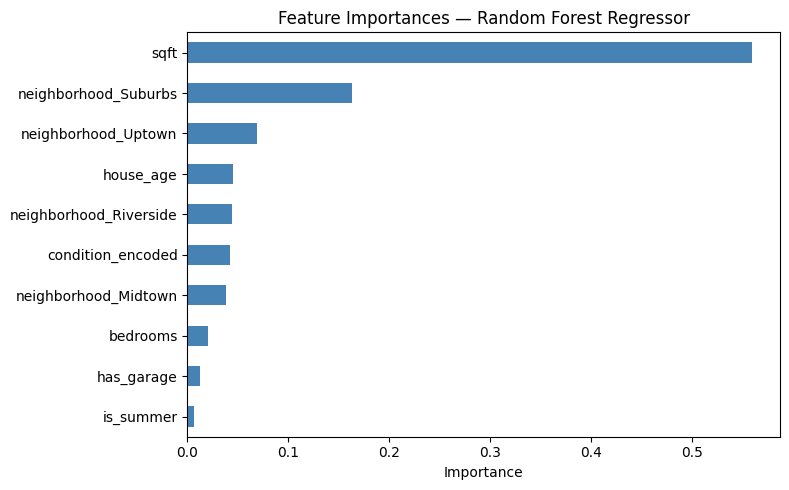

In [6]:
# Feature importance — how much each feature contributes to reducing prediction error
importances = pd.Series(rf_reg.feature_importances_, index=feature_cols).sort_values()
importances.plot(kind='barh', figsize=(8, 5), color='steelblue')
plt.title('Feature Importances — Random Forest Regressor')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

---
## Section 3: Classification
Classification predicts a discrete class. We evaluate with **accuracy** (fraction of correct predictions). For imbalanced classes, also check precision, recall, and F1 — covered in Model Evaluation.

### 3.1 Logistic Regression
Despite the name, logistic regression is a **classification** algorithm. It models the probability of belonging to a class using a sigmoid function, then thresholds at 0.5. Fast, interpretable, works well when classes are linearly separable.

In [7]:
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train, y_clf_train)

print('Logistic Regression')
print(f'  Train accuracy: {log_reg.score(X_train, y_clf_train):.4f}')
print(f'  Test  accuracy: {log_reg.score(X_test, y_clf_test):.4f}')

Logistic Regression
  Train accuracy: 0.8875
  Test  accuracy: 0.8900


### 3.2 Random Forest Classifier
Each tree votes for a class label. The final prediction is the majority vote across all trees.

In [8]:
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_clf.fit(X_train, y_clf_train)

print('Random Forest Classifier')
print(f'  Train accuracy: {rf_clf.score(X_train, y_clf_train):.4f}')
print(f'  Test  accuracy: {rf_clf.score(X_test, y_clf_test):.4f}')

Random Forest Classifier
  Train accuracy: 1.0000
  Test  accuracy: 0.8500


---
## Section 4: Cross-Validation
A single train/test split can be misleading — results depend on which rows land in each set. **Cross-validation** (CV) runs multiple splits and averages the scores, giving a more reliable estimate of model performance.

**K-Fold CV**: splits data into k folds. Each fold takes a turn as the test set while the remaining k−1 folds train. Final score = mean across all k folds.

In [9]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Regression — 5-fold CV
cv_r2 = cross_val_score(rf_reg, X, y_reg, cv=kf, scoring='r2')
print('Random Forest Regressor — 5-Fold CV')
print(f'  Fold R²:  {cv_r2.round(4)}')
print(f'  Mean R²:  {cv_r2.mean():.4f} ± {cv_r2.std():.4f}')

print()

# Classification — 5-fold CV
cv_acc = cross_val_score(rf_clf, X, y_clf, cv=kf, scoring='accuracy')
print('Random Forest Classifier — 5-Fold CV')
print(f'  Fold acc: {cv_acc.round(4)}')
print(f'  Mean acc: {cv_acc.mean():.4f} ± {cv_acc.std():.4f}')

Random Forest Regressor — 5-Fold CV
  Fold R²:  [0.8453 0.7646 0.8462 0.8492 0.8519]
  Mean R²:  0.8314 ± 0.0335



Random Forest Classifier — 5-Fold CV
  Fold acc: [0.86 0.82 0.87 0.84 0.87]
  Mean acc: 0.8520 ± 0.0194


---
## Section 5: Hyperparameter Tuning
**Hyperparameters** control the model's structure and are set before training — unlike model weights which are learned during training. Examples: `n_estimators`, `max_depth`, `alpha`.

`GridSearchCV` exhaustively tries all parameter combinations, evaluating each with cross-validation. Returns the best-performing configuration.

In [10]:
param_grid = {
    'n_estimators': [50, 100],
    'max_depth':    [None, 10, 20],
    'min_samples_split': [2, 5]
}

grid_search = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)
grid_search.fit(X_train, y_reg_train)

print(f'Best parameters:    {grid_search.best_params_}')
print(f'Best CV R²:         {grid_search.best_score_:.4f}')
print(f'Test R² (best model): {grid_search.best_estimator_.score(X_test, y_reg_test):.4f}')

Best parameters:    {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}
Best CV R²:         0.8238
Test R² (best model): 0.8497


---
## Section 6: Common Mistakes
- **Data leakage**: using information from the test set during training (e.g. fitting a scaler on all data before splitting). Always fit preprocessing on train only, then transform both train and test.
- **Evaluating on train set only**: train score alone tells you nothing about generalization. Always report test or CV scores.
- **Ignoring class imbalance**: if 95% of labels are class 0, a model that always predicts 0 gets 95% accuracy but is useless. Check class distribution and use precision/recall/F1.
- **Tuning on the test set**: if you use test results to choose hyperparameters, the test set becomes a de facto training set. Use CV for tuning — the test set is for final evaluation only.